**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**15 | Nested Training-Data Scaling: Random Forest and Weighted CNN**

![Nested training-data scale comparison workflow](https://raw.githubusercontent.com/RezaSaadatyar/human-movement-intelligence/main/wearable_activity_recognition/images/15_workflow.svg)

**Objective:** Compare maximum Train sizes of 500 and 1,000 windows per participant for Random Forest and weighted CNN while keeping the six Validation participants and their source windows fixed.

**Dataset:** HARTH v2.0 Development recordings from 29 participants, with nested sampling and S023/S032 excluded. The shared Validation set contains 2,701 windows.

**Notebook Scope:** Verify nesting of Train windows, compare changes in class support and evaluate four model-size conditions on identical Validation rows. This is a Development ablation; equal epoch counts do not imply equal optimiser-update budgets.

**00. Colab Repository Setup**

In [89]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports and Research Environment**

In [90]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 3. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

plot_style(font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10, 
    figure_dpi=100, figure_size=(9, 4))

# ---------- 4.  Machine Learning, Deep Learning Models and Metrics -----------
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, balanced_accuracy_score
import torch

# ------------------ 5. HARTH and Shared Research Utilities -------------------
from core.output_download import download_outputs_from_colab
from harth_data import HARTH_SUBJECTS, SENSOR_COLUMNS, ACTIVITY_NAMES, prepare_harth_nested_window_cohort
from core.data_splitting import split_group_indices
from core.feature_engineering import extract_signal_features
from core.temporal_cnn import train_temporal_cnn
from core.ml_baselines import classification_class_report, evaluate_predictions_by_subject
from core.group_cross_validation import compare_models_by_subject

# ------------------- 6. Training Device and Setup Summary --------------------
from core.computer_device import computer_device
device = computer_device()
DEVICE = device.type

# -------------------- 7. Output Directory and Setup Summary ------------------
output_dir = root / "wearable_activity_recognition" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
print("Research output directory:", output_dir)

Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.11.0+cu128
CUDA device: Tesla T4
CUDA runtime: 12.8
cuDNN version: 91900
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
Research output directory: /content/human-movement-intelligence/wearable_activity_recognition/output


**02. Construct Strictly Nested Development Windows**

Create label-pure windows independently for each participant and remove out-of-task classes after segmentation. All 500-cap windows remain present in the expanded 1,000-cap cohort; additional positions are selected without class-targeted resampling.

In [91]:
# ================ 02. Build Nested Development Signal Windows ================

# ---------------------- 1. Configure Development Cohort ----------------------
RESERVED_TEST = {"S023", "S032"}
DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)
TASK_CLASSES = tuple(range(1, 9))

# ---------------------- 2. Build Nested Source Windows -----------------------
X, metadata, overview = prepare_harth_nested_window_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES,
    base_cap=500, expanded_cap=1000,  # Preserve cap-500 windows within the expanded cohort.
    window_size=100, step_size=50, sampling_rate=50,
)
assert metadata["subject_id"].nunique() == 29
assert not (set(metadata["subject_id"]) & RESERVED_TEST)

# ------------------------ 3. Summarise Nested Cohort -------------------------
assert overview["base_windows"].sum() == 14201

print("Expanded source window array:", X.shape)

display(overview)


Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 samples, 6 channels
Candid

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 2

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:424: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Expanded source window array: (28201, 6, 100)


,subject_id,eligible_windows,base_windows,expanded_windows,new_training_windows
0,S006,6708,500,1000,500
1,S008,7392,500,1000,500
2,S009,201,201,201,0
3,S010,6077,500,1000,500
4,S012,7309,500,1000,500
5,S013,6402,500,1000,500
6,S014,6299,500,1000,500
7,S015,7453,500,1000,500
8,S016,6272,500,1000,500
9,S017,6678,500,1000,500


**03. Keep Validation Participants and Source Rows Fixed**

Reproduce the original split from the 500-window cohort. Both conditions use the same 20 Train participants, six Validation participants and 2,701 Validation windows. The remaining three Development participants are unused.

In [92]:
# ================ 03. Freeze Identical Validation Source Rows ================

# ------------------- 1. Prepare Base Windows and Partition -------------------
base_mask = metadata["in_base_500"].to_numpy(dtype=bool)
base_row_ids = np.flatnonzero(base_mask)
original_parts = split_group_indices(
    metadata.iloc[base_row_ids]["subject_id"].to_numpy(),
    train_fraction=0.70, validation_fraction=0.20,
    test_fraction=0.10, random_state=42,
)

# ----------------------- 2. Verify Participant Groups ------------------------
train_people = set(metadata.iloc[base_row_ids[original_parts["train"]]]["subject_id"])
validation_people = set(metadata.iloc[base_row_ids[original_parts["validation"]]]["subject_id"])
unused_people = set(metadata.iloc[base_row_ids[original_parts["test"]]]["subject_id"])
assert len(train_people) == 20 and len(validation_people) == 6 and len(unused_people) == 3
assert not (train_people & validation_people or train_people & unused_people or validation_people & unused_people)
person_ids = metadata["subject_id"].to_numpy()

# --------------------- 3. Freeze Validation Source Rows ----------------------
validation_rows = np.flatnonzero(base_mask & np.isin(person_ids, list(validation_people)))  # Keep identical original Validation rows for both scales.

# ------------------- 4. Construct Nested Training Windows --------------------
base_train_rows = np.flatnonzero(base_mask & np.isin(person_ids, list(train_people)))
expanded_train_rows = np.flatnonzero(np.isin(person_ids, list(train_people)))
assert np.isin(base_train_rows, expanded_train_rows).all()
assert len(validation_rows) == 2701
print("Train people:", sorted(train_people))
print("Validation people:", sorted(validation_people))
print("Train windows (base/expanded):", len(base_train_rows), len(expanded_train_rows))
print("Validation windows (fixed):", len(validation_rows))


Independent groups: 29
train: 20 groups | 10,000 rows
validation: 6 groups | 2,701 rows
test: 3 groups | 1,500 rows
Train people: ['S006', 'S010', 'S013', 'S014', 'S015', 'S017', 'S018', 'S020', 'S024', 'S025', 'S026', 'S027', 'S028', 'S029', 'S030', 'S031', 'S033', 'S034', 'S035', 'S038']
Validation people: ['S009', 'S012', 'S019', 'S022', 'S036', 'S037']
Train windows (base/expanded): 10000 20000
Validation windows (fixed): 2701


**04. Inspect Class Support Added to Train**

Compare the 10,000- and 20,000-window Train sets by activity. Only training support changes; the Validation records, labels and participant identities are held constant.

In [93]:
# ============== 04. Audit Activity Counts in the Two Train Sets ==============

# --------------------- 1. Compare Training Class Support ---------------------
train_class_counts = pd.DataFrame({
    "base_train": metadata.iloc[base_train_rows]["label"].value_counts(),
    "expanded_train": metadata.iloc[expanded_train_rows]["label"].value_counts(),
    "fixed_validation": metadata.iloc[validation_rows]["label"].value_counts(),
}).reindex(TASK_CLASSES).fillna(0).astype(int)

train_class_counts.index = [f"{code}: {ACTIVITY_NAMES[code]}" for code in TASK_CLASSES]
train_class_counts["new_train_windows"] = (
    train_class_counts["expanded_train"] - train_class_counts["base_train"]
)

# ---------------------- 2. Check Nested Data Expansion -----------------------
display(train_class_counts)

assert (train_class_counts["base_train"] > 0).all()
assert (train_class_counts["new_train_windows"] >= 0).all()


,base_train,expanded_train,fixed_validation,new_train_windows
1: Walking,2987,5983,453,2996
2: Running,940,1875,78,935
3: Shuffling,169,328,15,159
4: Stairs ascending,156,309,30,153
5: Stairs descending,145,292,32,147
6: Standing,1502,3019,536,1517
7: Sitting,3240,6475,1363,3235
8: Lying,861,1719,194,858


**05. Fit Random Forest at Two Training Sizes**

Apply the same 30 statistical features and Random Forest hyperparameters in both conditions. Evaluate both fits on the fixed Validation windows.

In [94]:
# =============== 05. Fit Random Forest at Two Training Scales ================

# ---------------------- 1. Prepare Matched RF Features -----------------------
features = extract_signal_features(X, channel_names=SENSOR_COLUMNS)
y = metadata["label"].to_numpy()

# ------------------------ 2. Configure RF Conditions -------------------------
rf_predictions = {}

# ------------------------- 3. Fit RF Training Scales -------------------------
for name, train_rows in [("Train 500", base_train_rows), ("Train 1000", expanded_train_rows)]:
    forest = RandomForestClassifier(
        n_estimators=120, min_samples_leaf=3,
        class_weight="balanced_subsample", random_state=42, n_jobs=-1
    )
    forest.fit(features.iloc[train_rows], y[train_rows])
    rf_predictions[name] = forest.predict(features.iloc[validation_rows])
    print(name, "RF Validation Macro F1:",
          round(f1_score(y[validation_rows], rf_predictions[name],
                         labels=TASK_CLASSES, average="macro", zero_division=0), 4))


Input windows: (28201, 6, 100)
Feature matrix: (28201, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Train 500 RF Validation Macro F1: 0.814
Train 1000 RF Validation Macro F1: 0.8644


**06. Train Weighted CNNs on Nested Train Sets**

Fit channel scaling and inverse-square-root class weights separately from each Train set. Keep architecture, seed, epoch count and Validation records constant, while acknowledging that the larger Train set involves more optimiser updates per epoch.

In [95]:
# ================ 06. Train Two Class-Weighted Temporal CNNs =================

# ------------------- 1. Configure Weighted CNN Experiments -------------------
cnn_predictions, histories = {}, {}
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------- 2. Train Nested CNN Conditions -----------------------
for name, train_rows in [("Train 500", base_train_rows), ("Train 1000", expanded_train_rows)]:
    print("Weighted CNN:", name)
    model, history, prediction, scaling = train_temporal_cnn(
        X_train=X[train_rows], y_train=y[train_rows],
        X_validation=X[validation_rows], y_validation=y[validation_rows],
        classes=TASK_CLASSES, epochs=5, batch_size=128,
        learning_rate=1e-3, seed=42, device=DEVICE,
        class_weighting="inverse_sqrt",
    )
    cnn_predictions[name] = prediction
    histories[name] = history
    display(history.round(4))


Weighted CNN: Train 500
Epoch 1/5 | loss=0.9723 | validation Macro F1=0.5930
Epoch 2/5 | loss=0.5297 | validation Macro F1=0.6233
Epoch 3/5 | loss=0.4122 | validation Macro F1=0.6744
Epoch 4/5 | loss=0.3386 | validation Macro F1=0.7334
Epoch 5/5 | loss=0.2894 | validation Macro F1=0.8000


,epoch,train_loss,validation_macro_f1,validation_accuracy,validation_balanced_accuracy
0,1,0.9723,0.5930,0.9371,0.6006
1,2,0.5297,0.6233,0.9397,0.6228
2,3,0.4122,0.6744,0.9482,0.6543
3,4,0.3386,0.7334,0.9419,0.7132
4,5,0.2894,0.8000,0.9537,0.8126


Weighted CNN: Train 1000
Epoch 1/5 | loss=0.7662 | validation Macro F1=0.6382
Epoch 2/5 | loss=0.3719 | validation Macro F1=0.7389
Epoch 3/5 | loss=0.2638 | validation Macro F1=0.8105
Epoch 4/5 | loss=0.2167 | validation Macro F1=0.8428
Epoch 5/5 | loss=0.1793 | validation Macro F1=0.7809


,epoch,train_loss,validation_macro_f1,validation_accuracy,validation_balanced_accuracy
0,1,0.7662,0.6382,0.9419,0.6279
1,2,0.3719,0.7389,0.9541,0.7099
2,3,0.2638,0.8105,0.9541,0.7895
3,4,0.2167,0.8428,0.9656,0.8360
4,5,0.1793,0.7809,0.9548,0.8100


**07. Compare Four Conditions on Fixed Validation Data**

Final-epoch Validation Macro F1 was 0.8266 and 0.8644 for Random Forest at 500 and 1,000 windows, and 0.7968 and 0.7805 for weighted CNN. The larger CNN reached 0.8428 at epoch four, but the specified comparison uses final-epoch predictions. This is an observed Development difference, not proof of a causal scaling benefit.

,model,validation_macro_f1,balanced_accuracy,validation_windows
0,RF 500,0.8140,0.8259,2701
1,RF 1000,0.8644,0.8725,2701
2,Weighted CNN 500,0.8000,0.8126,2701
3,Weighted CNN 1000,0.7809,0.8100,2701


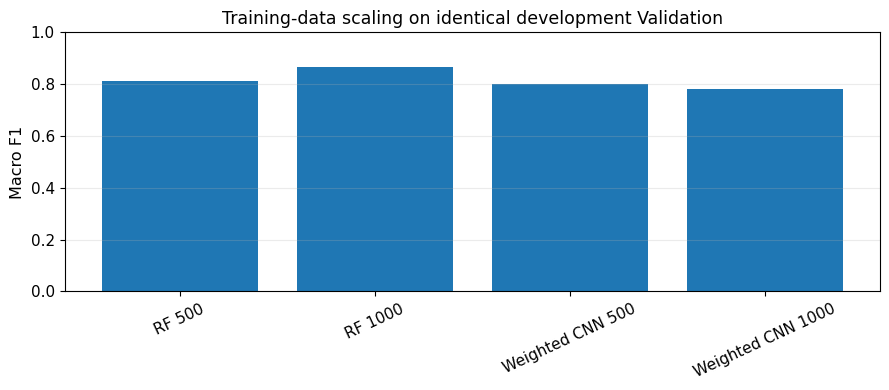

In [96]:
# =============== 07. Compare Four Fixed-Validation Conditions ================

# ------------------ 1. Compare Fixed Validation Predictions ------------------
prediction_sets = {
    "RF 500": rf_predictions["Train 500"],
    "RF 1000": rf_predictions["Train 1000"],
    "Weighted CNN 500": cnn_predictions["Train 500"],
    "Weighted CNN 1000": cnn_predictions["Train 1000"],
}
y_val = y[validation_rows]

# --------------------- 2. Calculate Matched Performance ----------------------
results = pd.DataFrame([
    {"model": name, "validation_macro_f1": f1_score(
         y_val, predicted, labels=TASK_CLASSES, average="macro", zero_division=0),
     "balanced_accuracy": balanced_accuracy_score(y_val, predicted),
     "validation_windows": len(y_val)}
    for name, predicted in prediction_sets.items()
])

display(results.round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(results["model"], results["validation_macro_f1"])
ax.set(title="Training-data scaling on identical development Validation",
       ylabel="Macro F1", ylim=(0, 1))
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
save_figure(fig, output_dir / "15_nested_training_scale_macro_f1.png")
plt.show()


**08. Inspect Class and Participant-Level Changes**

Compare class-specific and paired participant scores using identical Validation support. Random Forest at 1,000 windows scored higher for five of six participants; the larger weighted CNN improved for three and declined for three.

In [97]:
# =============== 08. Inspect Class and Participant F1 Changes ================

# ----------------- 1. Prepare Class and Participant Results ------------------
class_tables = []
person_tables = []
val_people_ids = metadata.iloc[validation_rows]["subject_id"].to_numpy()

# ---------------------- 2. Evaluate Class-Level Changes ----------------------
for name, predicted in prediction_sets.items():
    class_result = classification_class_report(
        y_val, predicted, classes=TASK_CLASSES,
        class_names=[ACTIVITY_NAMES[c] for c in TASK_CLASSES]
    )
    class_result["model"] = name
    class_tables.append(class_result)
    person_tables.append(evaluate_predictions_by_subject(
        y_val, predicted, val_people_ids, TASK_CLASSES, name
    ))
classes_report = pd.concat(class_tables, ignore_index=True)
people_report = pd.concat(person_tables, ignore_index=True)

display(classes_report[["model","class","support","precision","recall","f1"]].round(4))

# ------------------- 3. Compare Paired Participant Scores --------------------
paired_tables, paired_summaries = [], []
for larger, smaller in [("RF 1000","RF 500"), ("Weighted CNN 1000","Weighted CNN 500")]:
    paired, summary = compare_models_by_subject(
        people_report, model_a=larger, model_b=smaller
    )
    display(pd.DataFrame([summary]).round(4))
    display(paired.round(4))
    paired_table = paired.copy()
    paired_table["model_a"] = larger
    paired_table["model_b"] = smaller
    paired_tables.append(paired_table)
    paired_summaries.append({"model_a": larger, "model_b": smaller, **summary})


,model,class,support,precision,recall,f1
0,RF 500,Walking,453,0.9259,0.9382,0.9320
1,RF 500,Running,78,0.9750,1.0000,0.9873
2,RF 500,Shuffling,15,0.2500,0.7333,0.3729
3,RF 500,Stairs ascending,30,1.0000,0.2667,0.4211
4,RF 500,Stairs descending,32,1.0000,0.6875,0.8148
5,RF 500,Standing,536,0.9869,0.9851,0.9860
6,RF 500,Sitting,1363,0.9993,0.9963,0.9978
7,RF 500,Lying,194,1.0000,1.0000,1.0000
8,RF 1000,Walking,453,0.9495,0.9536,0.9515
9,RF 1000,Running,78,0.9750,1.0000,0.9873


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,RF 1000,RF 500,macro_f1_fixed_task,6,0.0401,0.0503,5,1,0


,subject_id,score_a,score_b,difference_a_minus_b
0,S009,0.4123,0.3556,0.0567
1,S012,0.8388,0.8605,-0.0217
2,S019,0.9416,0.8680,0.0736
3,S022,0.8378,0.7516,0.0863
4,S036,0.6196,0.6180,0.0016
5,S037,0.8572,0.8132,0.0440


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Weighted CNN 1000,Weighted CNN 500,macro_f1_fixed_task,6,0.0118,0.0058,3,3,0


,subject_id,score_a,score_b,difference_a_minus_b
0,S009,0.3190,0.3297,-0.0107
1,S012,0.9173,0.8951,0.0222
2,S019,0.8774,0.8374,0.0401
3,S022,0.8589,0.9012,-0.0422
4,S036,0.5774,0.4898,0.0876
5,S037,0.7557,0.7817,-0.0261


**09. Scientific Quality Gate and Limitations**

Verify nested Train rows, identical Validation source indices, participant separation and reserved Test exclusion. This previously examined Development split cannot establish an independent Test improvement or a general scaling relationship.

In [98]:
# ============= 09. Nested Training-Data Scientific Quality Gate ==============

# ---------------- 1. Verify Fixed Validation and Nested Data -----------------
assert len(base_train_rows) == 10000
assert len(validation_rows) == 2701
assert np.isin(base_train_rows, expanded_train_rows).all()

# ---------------------- 2. Check Participant Separation ----------------------
assert not (set(val_people_ids) & train_people)
assert not (set(val_people_ids) & RESERVED_TEST)
assert all(len(predicted) == len(y_val) for predicted in prediction_sets.values())
assert results["validation_macro_f1"].between(0, 1).all()

# ---------------------- 3. Quality Gate and Boundaries -----------------------
print("Nested training-data size ablation: PASSED")
print("Validation identities and original Test protection: PASSED")
print("Independent full-dataset generalisation: NOT ESTABLISHED")

# -------------------- 4. Export Nested Training Comparison ------------------
overview.to_csv(output_dir / "15_nested_development_cohort_summary.csv", index=False)
train_class_counts.rename_axis("activity").reset_index().to_csv(
    output_dir / "15_nested_train_class_coverage.csv", index=False
)
results.to_csv(output_dir / "15_nested_validation_model_metrics.csv", index=False)
classes_report.to_csv(output_dir / "15_nested_validation_class_metrics.csv", index=False)
people_report.to_csv(output_dir / "15_nested_validation_subject_metrics.csv", index=False)
pd.concat(paired_tables, ignore_index=True).to_csv(
    output_dir / "15_nested_paired_subject_comparisons.csv", index=False
)
pd.DataFrame(paired_summaries).to_csv(
    output_dir / "15_nested_paired_summary.csv", index=False
)
for name, table in histories.items():
    safe_name = "500" if name == "Train 500" else "1000"
    table.to_csv(
        output_dir / f"15_weighted_cnn_training_history_{safe_name}.csv", index=False
    )
pd.DataFrame({
    "subject_id": np.tile(val_people_ids, len(prediction_sets)),
    "true_source_code": np.tile(y_val, len(prediction_sets)),
    "model": np.repeat(list(prediction_sets.keys()), len(y_val)),
    "predicted_source_code": np.concatenate(list(prediction_sets.values())),
}).to_csv(output_dir / "15_nested_validation_predictions.csv", index=False)
print("Saved fixed-Validation nested training evidence in:", output_dir)

download_outputs_from_colab(folder="wearable_activity_recognition/output", stage="15")

Nested training-data size ablation: PASSED
Validation identities and original Test protection: PASSED
Independent full-dataset generalisation: NOT ESTABLISHED
Saved fixed-Validation nested training evidence in: /content/human-movement-intelligence/wearable_activity_recognition/output
